# **03 · Optimización de hiperparámetros con Optuna**

Busca los hiperparámetros que mejoran al modelo base del notebook 02.

**¿Por qué Optuna y no Grid Search?** Cada prueba es un entrenamiento completo (varios minutos de GPU). Una
grilla de 5 hiperparámetros con 3 valores cada uno serían 243 entrenamientos. Optuna usa búsqueda bayesiana
(TPE): con los resultados de las pruebas anteriores elige qué valores probar después, y llega a una buena
zona con muchas menos pruebas.

| Elemento | Definición |
|---|---|
| **Métrica que se maximiza** | mAP50-95 sobre las 10 fotos propias de validación |
| **Métricas que se registran** | precisión, recobrado, F1, mAP50 y mAP50-95 |
| **Pruebas** | 12 entrenamientos de 30 épocas como máximo (la primera, con los valores del modelo base) |
| **Salida** | `results/optuna_pruebas.csv` (una fila por prueba) y `results/mejores_hiperparametros.json` |

## **1. Preparación del entorno**

In [ ]:
!pip -q install "ultralytics==8.4.153" optuna

In [ ]:
# Carpetas del proyecto. En Colab todo queda en Drive (carpeta limon_ia), con la misma estructura
# que el repositorio: data/, results/ y runs/ (modelos entrenados). Fuera de Colab se usa el repositorio.
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/limon_ia")   # carpeta del proyecto en Drive
    TRABAJO = Path("/content")                        # disco de Colab: rápido, pero se borra al cerrar
except ImportError:
    BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    TRABAJO = BASE / "data"

DATA, RESULTS, RUNS = BASE / "data", BASE / "results", BASE / "runs"
for carpeta in (DATA, RESULTS, RUNS):
    carpeta.mkdir(parents=True, exist_ok=True)
DATOS = TRABAJO / "datos"                             # dataset unificado, descomprimido
print("Proyecto en", BASE)

Mounted at /content/drive
Proyecto en /content/drive/MyDrive/limon_ia


In [ ]:
import json
import shutil

import optuna
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from ultralytics import YOLO

IMGSZ = 640            # tamaño de imagen, igual que el modelo base
N_PRUEBAS = 12         # cantidad de entrenamientos de la búsqueda
EPOCAS_PRUEBA = 30     # épocas máximas de cada prueba (el modelo base llegó a su mejor época cerca de la 30)
PACIENCIA_PRUEBA = 10  # parada temprana de cada prueba
EPOCAS_FINAL = 60      # épocas máximas del entrenamiento final, igual que el modelo base
PACIENCIA_FINAL = 20

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
# --------
# Función que deja listo el dataset para entrenar.
#   - Descomprime data/datos_limon.zip (lo genera el notebook 01) si todavía no está en el disco.
#   - Repite "repetir" veces las fotos propias de entrenamiento (sobremuestreo), para que pesen más
#     frente a las 915 imágenes del dataset base.
#   - Devuelve: la ruta del archivo .yaml que le dice a YOLO dónde están train y val.
# --------
def preparar_datos(repetir=3):
    if not (DATOS / "propio").exists():
        shutil.unpack_archive(DATA / "datos_limon.zip", DATOS)
    rep = DATOS / "propio" / f"train_x{repetir}"
    if not rep.exists():
        for sub in ("images", "labels"):
            (rep / sub).mkdir(parents=True)
        for img in sorted((DATOS / "propio" / "train" / "images").iterdir()):
            etiqueta = DATOS / "propio" / "train" / "labels" / (img.stem + ".txt")
            for k in range(repetir):
                shutil.copy(img, rep / "images" / f"r{k}_{img.name}")
                shutil.copy(etiqueta, rep / "labels" / f"r{k}_{img.stem}.txt")
    # train: todo el dataset base + las fotos propias de train repetidas. val: las 10 fotos propias de valid.
    train = [str(DATOS / "base" / s / "images") for s in ("train", "valid", "test")
             if any((DATOS / "base" / s / "images").glob("*"))] + [str(rep / "images")]
    ruta = TRABAJO / f"limones_x{repetir}.yaml"
    ruta.write_text(yaml.safe_dump({"train": train, "val": str(DATOS / "propio" / "valid" / "images"),
                                    "nc": 1, "names": {0: "limon"}}))
    return str(ruta)


# --------
# Función que evalúa un modelo sobre una o más carpetas de imágenes.
#   - Recibe: el modelo, un nombre para la fila y los conjuntos propios a usar ("valid", "test").
#   - Devuelve: diccionario con precisión, recobrado, F1, mAP50 y mAP50-95.
# --------
def evaluar(modelo, nombre, conjuntos):
    carpetas = [str(DATOS / "propio" / c / "images") for c in conjuntos]
    ruta = TRABAJO / f"eval_{'_'.join(conjuntos)}.yaml"
    ruta.write_text(yaml.safe_dump({"train": carpetas, "val": carpetas, "nc": 1, "names": {0: "limon"}}))
    m = modelo.val(data=str(ruta), imgsz=IMGSZ, project=str(TRABAJO / "evals"), name=nombre, exist_ok=True,
                   verbose=False, plots=False)
    p, r = float(m.box.mp), float(m.box.mr)
    return {"modelo": nombre, "conjunto": "+".join(conjuntos),
            "imágenes": sum(len(list(Path(c).glob("*"))) for c in carpetas),
            "precisión": round(p, 3), "recobrado": round(r, 3), "F1": round(2 * p * r / (p + r + 1e-9), 3),
            "mAP50": round(float(m.box.map50), 3), "mAP50-95": round(float(m.box.map), 3)}

## **2. Espacio de búsqueda**

| Hiperparámetro | Qué controla | Rango | Valor base |
|---|---|---|---|
| `lr0` | Tasa de aprendizaje inicial: cuánto se corrigen los pesos en cada paso | 0,0003 a 0,01 (escala logarítmica) | 0,002 |
| `weight_decay` | Regularización: penaliza los pesos grandes para reducir el sobreajuste | 0,00005 a 0,005 (escala logarítmica) | 0,0005 |
| `hsv_h` | Aumento de datos: cuánto se varía al azar el **tono** de cada imagen | 0 a 0,08 | 0,015 |
| `scale` | Aumento de datos: cuánto se agranda o achica al azar cada imagen | 0,2 a 0,9 | 0,5 |
| `repetir` | Cuántas veces se repite cada foto propia de entrenamiento (sobremuestreo) | 1, 3 o 5 | 3 |

Los tres últimos se eligieron por lo que mostraron las features del notebook 01: `hsv_h` actúa sobre el tono,
`scale` sobre el tamaño de los limones y `repetir` sobre el peso de las fotos propias frente al dataset
público.

**Nota sobre el optimizador.** Con `optimizer="auto"` Ultralytics ignora `lr0` y elige todo solo: en el
modelo base eligió AdamW con tasa 0,002. Para que `lr0` y `weight_decay` tengan efecto, acá se fija
`optimizer="AdamW"`. Por eso la primera prueba usa los valores base con AdamW: es la referencia justa.

In [ ]:
VALORES_BASE = {"lr0": 0.002, "weight_decay": 0.0005, "hsv_h": 0.015, "scale": 0.5, "repetir": 3}


# --------
# Función que entrena un modelo con un conjunto de hiperparámetros.
#   - Recibe: los hiperparámetros, la carpeta y el nombre de la corrida, épocas máximas y paciencia.
#   - Devuelve: las métricas del mejor modelo (best.pt) en validación.
# --------
def entrenar(hp, proyecto, nombre, epocas, paciencia):
    modelo = YOLO("yolo26n.pt")
    m = modelo.train(
        data=preparar_datos(hp["repetir"]), epochs=epocas, patience=paciencia, imgsz=IMGSZ, batch=16, seed=0,
        optimizer="AdamW", lr0=hp["lr0"], weight_decay=hp["weight_decay"], hsv_h=hp["hsv_h"], scale=hp["scale"],
        project=str(proyecto), name=nombre, exist_ok=True, plots=False, verbose=False,
    )
    p, r = float(m.box.mp), float(m.box.mr)
    return {"precisión": p, "recobrado": r, "F1": 2 * p * r / (p + r + 1e-9),
            "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}


# --------
# Función objetivo: Optuna la llama una vez por prueba.
#   - Recibe: trial, el objeto con el que se piden los valores a probar.
#   - Devuelve: el valor a maximizar (mAP50-95 en validación).
# --------
def objetivo(trial):
    hp = {
        "lr0": trial.suggest_float("lr0", 3e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 5e-5, 5e-3, log=True),
        "hsv_h": trial.suggest_float("hsv_h", 0.0, 0.08),
        "scale": trial.suggest_float("scale", 0.2, 0.9),
        "repetir": trial.suggest_categorical("repetir", [1, 3, 5]),
    }
    metricas = entrenar(hp, TRABAJO / "pruebas", f"prueba_{trial.number:02d}", EPOCAS_PRUEBA, PACIENCIA_PRUEBA)
    # Guardamos todas las métricas en la prueba y borramos sus pesos (no se usan y ocupan lugar).
    for nombre, valor in metricas.items():
        trial.set_user_attr(nombre, round(valor, 4))
    shutil.rmtree(TRABAJO / "pruebas" / f"prueba_{trial.number:02d}" / "weights", ignore_errors=True)
    return metricas["mAP50-95"]

## **3. Búsqueda**

Las primeras 5 pruebas (la de los valores base y 4 al azar) exploran el espacio; las 7 siguientes las guía TPE
con lo aprendido. (Por defecto Optuna explora 10 pruebas al azar, demasiado para una búsqueda de solo 12.)

El estudio se guarda en una base de datos (`results/optuna.db`) después de cada prueba, junto con el CSV `results/optuna_pruebas.csv`.

In [ ]:
# La base de datos se usa en el disco local (rápido) y se copia a results/ después de cada prueba.
BD_LOCAL, BD_GUARDADA = TRABAJO / "optuna.db", RESULTS / "optuna.db"
if BD_GUARDADA.exists() and not BD_LOCAL.exists():
    shutil.copy(BD_GUARDADA, BD_LOCAL)

estudio = optuna.create_study(study_name="limon_yolo26n", storage=f"sqlite:///{BD_LOCAL}", load_if_exists=True,
                              direction="maximize",
                              sampler=optuna.samplers.TPESampler(seed=0, n_startup_trials=5))
if not estudio.trials:
    estudio.enqueue_trial(VALORES_BASE)        # la primera prueba: los valores del modelo base


# --------
# Función que arma la tabla de pruebas: una fila por prueba, con sus hiperparámetros y métricas.
# --------
def tabla_de_pruebas():
    filas = []
    for t in estudio.trials:
        if t.state == optuna.trial.TrialState.COMPLETE:
            filas.append({"prueba": t.number, **{hp: round(v, 6) for hp, v in t.params.items()}, **t.user_attrs,
                          "minutos": round((t.datetime_complete - t.datetime_start).total_seconds() / 60, 1)})
    columnas = ["prueba", *VALORES_BASE, "precisión", "recobrado", "F1", "mAP50", "mAP50-95", "minutos"]
    return pd.DataFrame(filas, columns=columnas)


# Después de cada prueba: guardamos el CSV y la base de datos.
def guardar(estudio, trial):
    tabla_de_pruebas().to_csv(RESULTS / "optuna_pruebas.csv", index=False)
    shutil.copy(BD_LOCAL, BD_GUARDADA)


hechas = len(tabla_de_pruebas())
print(f"Pruebas hechas: {hechas} de {N_PRUEBAS}")
if hechas < N_PRUEBAS:
    estudio.optimize(objetivo, n_trials=N_PRUEBAS - hechas, callbacks=[guardar], catch=(RuntimeError,))

pruebas = tabla_de_pruebas()
pruebas.to_csv(RESULTS / "optuna_pruebas.csv", index=False)
pruebas.sort_values("mAP50-95", ascending=False).round(4)

[I 2026-11-17 23:18:48,131] A new study created in RDB with name: limon_yolo26n


Pruebas hechas: 0 de 12
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/limones_x3.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=t

[I 2026-11-17 23:29:02,553] Trial 0 finished with value: 0.7559249026159027 and parameters: {'lr0': 0.002, 'weight_decay': 0.0005, 'hsv_h': 0.015, 'scale': 0.5, 'repetir': 3}. Best is trial 0 with value: 0.7559249026159027.


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/limones_x3.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.04822107008573151, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0020554062603827007, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

[I 2026-11-17 23:38:57,902] Trial 1 finished with value: 0.7763478896812146 and parameters: {'lr0': 0.0020554062603827007, 'weight_decay': 0.0013469415096427058, 'hsv_h': 0.04822107008573151, 'scale': 0.5814182280978277, 'repetir': 3}. Best is trial 1 with value: 0.7763478896812146.


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/limones_x5.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.03067532150606222, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.006842005252111369, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

... (16 outputs left out)

[I 2026-11-18 01:10:29,345] Trial 10 finished with value: 0.7888478206456694 and parameters: {'lr0': 0.0007281834239878661, 'weight_decay': 0.0033516394853927685, 'hsv_h': 0.030121150309932593, 'scale': 0.8486457477103118, 'repetir': 5}. Best is trial 5 with value: 0.8030852177909809.


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/limones_x5.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.014675127325157949, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.00045763170336470145, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0

[I 2026-11-18 01:20:41,902] Trial 11 finished with value: 0.8300999280207833 and parameters: {'lr0': 0.00045763170336470145, 'weight_decay': 0.0001305362391823311, 'hsv_h': 0.014675127325157949, 'scale': 0.8540807039239279, 'repetir': 5}. Best is trial 11 with value: 0.8300999280207833.


,prueba,lr0,weight_decay,hsv_h,scale,repetir,precisión,recobrado,F1,mAP50,mAP50-95,minutos
11,11,0.0005,0.0001,0.0147,0.8541,5,0.9711,0.9828,0.9769,0.9922,0.8301,10.2
5,5,0.0005,0.0002,0.0135,0.8715,5,0.9817,0.9228,0.9513,0.9815,0.8031,10.8
3,3,0.0004,0.0001,0.0016,0.7828,5,0.9172,0.9556,0.9360,0.9773,0.8015,10.6
10,10,0.0007,0.0034,0.0301,0.8486,5,0.9907,0.9310,0.9599,0.9731,0.7888,10.0
7,7,0.0005,0.0001,0.0025,0.3643,5,1.0000,0.9058,0.9505,0.9765,0.7884,10.2
8,8,0.0035,0.0001,0.0404,0.7640,5,1.0000,0.8898,0.9417,0.9593,0.7795,10.0
1,1,0.0021,0.0013,0.0482,0.5814,3,0.9733,0.8793,0.9239,0.9726,0.7763,9.9
9,9,0.0014,0.0004,0.0567,0.7927,5,0.9307,0.9483,0.9394,0.9738,0.7742,8.4
6,6,0.0003,0.0020,0.0689,0.6452,5,0.9116,0.8894,0.9004,0.9452,0.7638,10.6
0,0,0.0020,0.0005,0.0150,0.5000,3,0.9636,0.9130,0.9376,0.9626,0.7559,10.2


## **4. Resultados de la búsqueda**

A la izquierda, el valor de cada prueba y el mejor acumulado: muestra si la búsqueda siguió mejorando. A la
derecha, la métrica contra cada hiperparámetro: si los puntos altos se agrupan en una zona, ese
hiperparámetro importa; si quedan dispersos, influye poco.

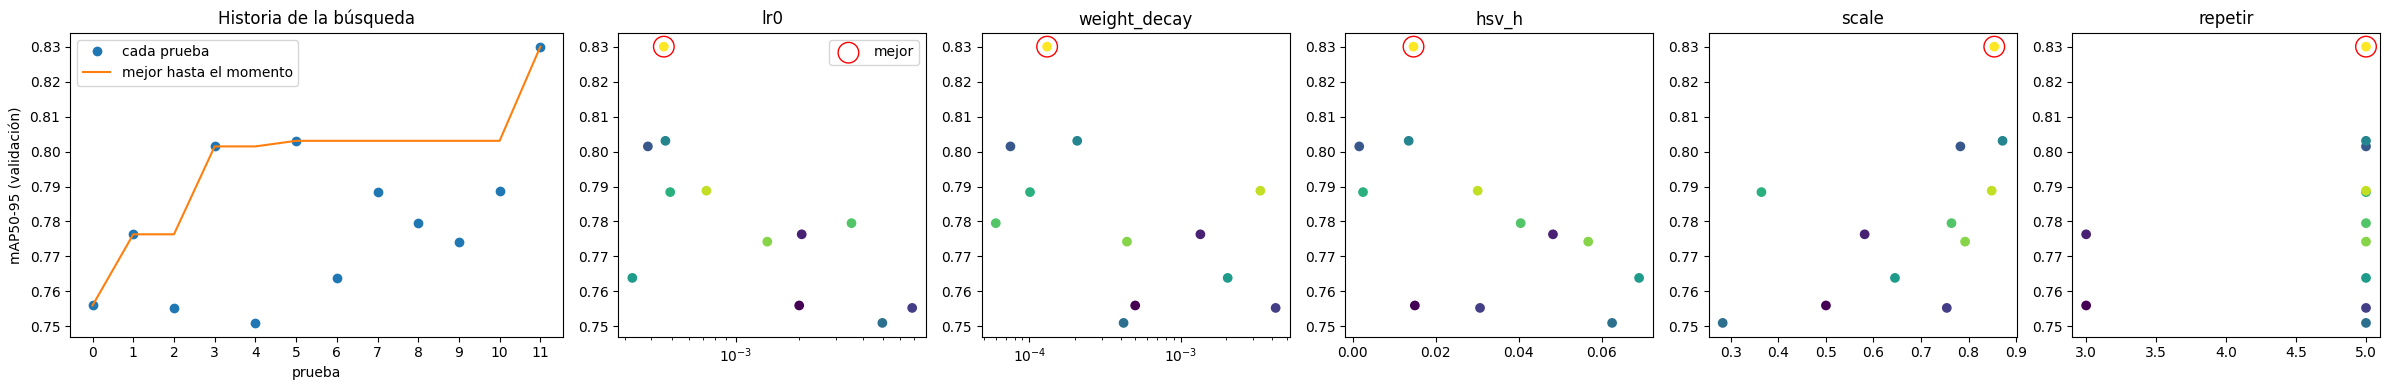

Mejor prueba: la 11, con mAP50-95 = 0.830
Valores base (prueba 0): mAP50-95 = 0.756 -> diferencia +0.074
{
  "lr0": 0.00045763170336470145,
  "weight_decay": 0.0001305362391823311,
  "hsv_h": 0.014675127325157949,
  "scale": 0.8540807039239279,
  "repetir": 5
}


In [ ]:
mejor = pruebas.loc[pruebas["mAP50-95"].idxmax()]
base = pruebas.loc[pruebas["prueba"] == 0].iloc[0] if (pruebas["prueba"] == 0).any() else None

fig, ejes = plt.subplots(1, 6, figsize=(24, 4), gridspec_kw={"width_ratios": [1.6, 1, 1, 1, 1, 1]})
ejes[0].plot(pruebas["prueba"], pruebas["mAP50-95"], "o", label="cada prueba")
ejes[0].plot(pruebas["prueba"], pruebas["mAP50-95"].cummax(), "-", label="mejor hasta el momento")
ejes[0].set_xlabel("prueba"); ejes[0].set_ylabel("mAP50-95 (validación)"); ejes[0].set_title("Historia de la búsqueda")
ejes[0].set_xticks(pruebas["prueba"]); ejes[0].legend()
for ax, hp in zip(ejes[1:], VALORES_BASE):
    ax.scatter(pruebas[hp], pruebas["mAP50-95"], c=pruebas["prueba"], cmap="viridis")
    ax.scatter([mejor[hp]], [mejor["mAP50-95"]], s=220, facecolors="none", edgecolors="red", label="mejor")
    if hp in ("lr0", "weight_decay"):
        ax.set_xscale("log")
    ax.set_title(hp)
ejes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS / "fig_optuna.png", dpi=110)
plt.show()

# Tomamos los valores exactos de la mejor prueba desde el estudio.
mejores_hp = estudio.trials[int(mejor["prueba"])].params
(RESULTS / "mejores_hiperparametros.json").write_text(json.dumps(mejores_hp, indent=2))
print(f"Mejor prueba: la {int(mejor['prueba'])}, con mAP50-95 = {mejor['mAP50-95']:.3f}")
if base is not None:
    print(f"Valores base (prueba 0): mAP50-95 = {base['mAP50-95']:.3f} "
          f"-> diferencia {mejor['mAP50-95'] - base['mAP50-95']:+.3f}")
print(json.dumps(mejores_hp, indent=2))

**Cuidado al interpretar.** La validación tiene solo 10 fotos (58 limones): una diferencia de uno o dos
limones mueve la métrica en el segundo decimal. Mejoras chicas respecto de la prueba 0 pueden ser ruido y no
un efecto real del hiperparámetro. Por eso la comparación final se hace en el notebook 04 sobre las fotos de
test, que no se usaron para elegir nada.

## **5. Entrenamiento final con los mejores hiperparámetros**

Se entrena de nuevo, ahora con el mismo máximo de épocas que el modelo base, y se guarda en
`runs/optimizado/`.

In [ ]:
mejor_opt = RUNS / "optimizado" / "weights" / "best.pt"
if mejor_opt.exists():
    print("Ya hay un modelo optimizado entrenado:", mejor_opt)
else:
    entrenar(mejores_hp, RUNS, "optimizado", EPOCAS_FINAL, PACIENCIA_FINAL)
shutil.copy(RUNS / "optimizado" / "results.csv", RESULTS / "optimizado_curvas.csv")
print("Curvas guardadas en", RESULTS / "optimizado_curvas.csv")

# Comparación preliminar en validación (la definitiva, en test, está en el notebook 04).
filas = [evaluar(YOLO(str(mejor_opt)), "optimizado", ["valid"])]
if (RUNS / "base" / "weights" / "best.pt").exists():
    filas.insert(0, evaluar(YOLO(str(RUNS / "base" / "weights" / "best.pt")), "base", ["valid"]))
comparacion = pd.DataFrame(filas)
comparacion.to_csv(RESULTS / "comparacion_validacion.csv", index=False)
comparacion

New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/limones_x5.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.014675127325157949, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.00045763170336470145, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0

,modelo,conjunto,imágenes,precisión,recobrado,F1,mAP50,mAP50-95
0,base,valid,10,1.000,0.923,0.960,0.974,0.778
1,optimizado,valid,10,0.982,0.966,0.974,0.992,0.811


**Análisis.** Ganó la **prueba 11** (lr0 = 0,00046, weight_decay = 0,00013, hsv_h = 0,015, scale = 0,85, repetir = 5), con mAP50-95 = 0,830 en validación. La prueba 0 (valores base) dio 0,756: la mejora es de 0,074.

Qué parece importar:
- **lr0:** las cuatro mejores pruebas tienen lr0 menor a 7,5e-4; las de lr0 ≥ 2e-3 dieron los peores resultados (0,751 a 0,776). Es el hiperparámetro con tendencia más clara.
- **scale:** casi todas las mejores usan valores altos (0,78 a 0,87); tiene sentido, porque las fotos propias tienen limones más chicos que el dataset público.
- **repetir:** 5 repeticiones de las fotos propias fueron mejores que 3 en general.
- **hsv_h** y **weight_decay**: sin tendencia clara con tan pocas pruebas.

En el entrenamiento final (60 épocas) el modelo llegó a 0,811 en validación (el óptimo de la búsqueda fue 0,830, algo optimista porque se eligió justamente por ese valor) contra 0,778 del base. La mejora se mantiene, pero es menor. Son solo 12 pruebas con una semilla cada una, así que diferencias de 0,01 a 0,02 están dentro del ruido.